# Step 7: Anomaly detection and evaluation

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

This notebook answers the two research questions:

1. **Do day types discovered by clustering detect meaningful anomalies better than contexts built from calendar and weather labels?**
2. **Which rider group, casual or registered, drives each anomaly?**

## The rules, fixed before any result was looked at

To keep the evaluation honest, every choice below was decided before running it, and nothing was tuned afterwards to improve the scores.

| Choice | Decision |
| --- | --- |
| Contexts compared | **learned** (the 5 GMM day types, Step 5), **calendar** (working day x season x wet or dry, 16 groups), and **none** (all days in one group, as a reference) |
| What is compared within a context | each day's shape and level against the median day of its context |
| Detectors | distance to the context median, kNN, LOF, Isolation Forest, and an ensemble of all four (Anomaly Detection 1 and 2) |
| Ground truth | **main:** the 10 verified outside events (16 event-days) from `events_reference.csv`; **secondary:** the same plus the 21 dataset holidays (37 event-days) |
| Metrics | precision, recall and F-measure on the top *k* days, for k = 20 and k = 37 (Anomaly Detection 2, Slides 96 to 101) |
| Explanation of flagged days | verified event; *plausible* if at least 3 daytime hours of rain or snow, a temperature at least 4 °C away from normal for the season, within 1 day of a holiday, or a bridge day; otherwise *unexplained* |

The same detectors and settings are used for every context, so the **only** thing that differs between the compared methods is the definition of "normal".

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, AQUA, YELLOW, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
SEED = 0

feat = pd.read_csv("features_day.csv", index_col="dteday", parse_dates=True)
clusters = pd.read_csv("clusters_all.csv", index_col="dteday", parse_dates=True)
events = pd.read_csv("events_reference.csv")
shape = {g: pd.read_csv(f"shape_{g}.csv", index_col="dteday", parse_dates=True) for g in ["all", "casual", "registered"]}

def event_days(df):
    return {d for r in df.itertuples() for d in pd.date_range(r.start_date, r.end_date)}

OUTSIDE = event_days(events[events.type != "holiday"])
ALL_EVENTS = event_days(events)
print(f"Outside events: {len(events[events.type != 'holiday'])} events, {len(OUTSIDE)} event-days")
print(f"With holidays:  {len(events)} events, {len(ALL_EVENTS)} event-days")

Outside events: 10 events, 16 event-days
With holidays:  31 events, 37 event-days


## 1. The three contexts

In [2]:
wet = np.where(feat.bad_weather_daytime_hours >= 1, "wet", "dry")
season_name = feat.season.map({1: "winter", 2: "spring", 3: "summer", 4: "autumn"})
CONTEXTS = {
    "learned": feat.day_type,
    "calendar": feat.workingday.map({1: "working", 0: "day off"}) + " | " + season_name + " | " + wet,
    "none": pd.Series("all days", index=feat.index),
}
for name, ctx in CONTEXTS.items():
    sizes = ctx.value_counts()
    print(f"{name:9s}: {len(sizes):2d} groups, smallest {sizes.min():3d} days, largest {sizes.max():3d} days")

learned  :  5 groups, smallest  29 days, largest 235 days
calendar : 16 groups, smallest  11 days, largest  95 days
none     :  1 groups, smallest 731 days, largest 731 days


The calendar baseline has **16 groups** and the learned contexts only **5**. The calendar groups are more specific (they even include wet or dry), so if anything this gives the baseline an advantage. Every group has at least 11 days, enough to define a typical day.

## 2. How far is each day from normal in its context?

For each day, two things are compared with the **median day of its context**:

- **shape residual:** the day's 24 hourly shares minus the context's median shares;
- **level residual:** the day's level minus the context's median level.

Each of the 25 residual columns is divided by its robust spread (the median absolute deviation, MAD), so hours with naturally large variation do not dominate. The level column is then multiplied by sqrt(24), so that the size of a day counts as much as its whole 24-hour pattern together: a day can be unusual in how people ride, in how many ride, or both.

The median is used instead of the mean so that the anomalies themselves do not pull the definition of normal towards them.

In [3]:
def mad(x):
    return 1.4826 * (x - x.median()).abs().median()

def residuals(context, group="all"):
    s = shape[group]
    lv = feat[f"level_{group}"]
    shape_res = s - s.groupby(context).transform("median")
    level_res = lv - lv.groupby(context).transform("median")
    scaled = shape_res / shape_res.apply(mad)
    return np.column_stack([scaled.values, (level_res / mad(level_res)).values * np.sqrt(s.shape[1])])

R = {name: residuals(ctx) for name, ctx in CONTEXTS.items()}
print({name: m.shape for name, m in R.items()})

{'learned': (731, 25), 'calendar': (731, 25), 'none': (731, 25)}


## 3. Detectors

Four detectors from the course score every day on its residuals (higher = more anomalous):

| Detector | Idea | Slides |
| --- | --- | --- |
| Distance to median | how far the day is from the typical day of its context | Anomaly Detection 1, 21 to 23 (statistical idea) |
| kNN | distance to the 10th nearest other day | Anomaly Detection 1, 53 to 64 |
| LOF | is the day in a sparser region than its neighbours? (20 neighbours) | Anomaly Detection 1, 65 to 90 |
| Isolation Forest | how quickly random splits isolate the day (500 trees) | Anomaly Detection 2, 80 to 85 |

**Ensemble:** each detector's scores are turned into ranks, and the four ranks are averaged. Combining several detectors is more robust than trusting one (ensemble idea, Anomaly Detection 2, Slides 86 to 94), and the course summary notes that no single detector is best for every dataset.

In [4]:
def detect(m, index):
    scores = pd.DataFrame(index=index)
    scores["distance"] = np.linalg.norm(m, axis=1)
    scores["kNN"] = NearestNeighbors(n_neighbors=11).fit(m).kneighbors(m)[0][:, -1]   # 10 others + itself
    scores["LOF"] = -LocalOutlierFactor(n_neighbors=20).fit(m).negative_outlier_factor_
    scores["iForest"] = -IsolationForest(n_estimators=500, random_state=SEED).fit(m).score_samples(m)
    scores["ensemble"] = scores.rank(pct=True).mean(axis=1)
    return scores

S = {name: detect(m, feat.index) for name, m in R.items()}
S["learned"]["GMM likelihood"] = -clusters.log_likelihood   # low likelihood = anomalous (Step 5)
DETECTORS = ["distance", "kNN", "LOF", "iForest", "ensemble"]
S["learned"].head()

,distance,kNN,LOF,iForest,ensemble,GMM likelihood
dteday,,,,,,
2011-01-01,27.555232,19.465057,2.117402,0.534856,0.965458,-5.973157
2011-01-02,12.104586,8.657435,1.463594,0.415119,0.783516,-8.963701
2011-01-03,5.579865,5.031841,1.196988,0.379880,0.480848,-11.923758
2011-01-04,6.867399,5.522822,1.287614,0.382937,0.573871,-10.417875
2011-01-05,6.737540,5.067497,1.145213,0.364998,0.462038,-11.567617


The learned context has one extra detector: the **GMM likelihood** from Step 5. A day that fits none of the five day types gets a low likelihood (Anomaly Detection 1, Slides 32 to 34). It has no calendar equivalent, so it is reported separately.

## 4. Evaluation against the verified outside events (main result)

For each method, the k highest-scoring days are taken as the detected anomalies:

- **precision** = share of the k detected days that are verified event-days;
- **recall** = share of the 16 verified event-days that are detected;
- **F-measure** = their harmonic mean.

In [5]:
def prf(score, reference, k):
    top = set(score.nlargest(k).index)
    hits = len(top & reference)
    p, r = hits / k, hits / len(reference)
    return p, r, (2 * p * r / (p + r) if hits else 0.0), hits

def evaluation_table(reference, k):
    rows = []
    for ctx in ["learned", "calendar", "none"]:
        for det in DETECTORS + (["GMM likelihood"] if ctx == "learned" else []):
            p, r, f1, hits = prf(S[ctx][det], reference, k)
            rows.append({"context": ctx, "detector": det, "hits": hits, "precision": p, "recall": r, "F": f1})
    return pd.DataFrame(rows)

main = {k: evaluation_table(OUTSIDE, k) for k in [20, 37]}
for k, t in main.items():
    print(f"\nTop {k} days: F-measure (outside events, {len(OUTSIDE)} event-days)")
    display(t.pivot(index="detector", columns="context", values="F").round(2)
             .loc[DETECTORS + ["GMM likelihood"]])


Top 20 days: F-measure (outside events, 16 event-days)


context,calendar,learned,none
detector,,,
distance,0.39,0.28,0.39
kNN,0.28,0.33,0.28
LOF,0.22,0.17,0.33
iForest,0.33,0.33,0.22
ensemble,0.33,0.33,0.22
GMM likelihood,NaN,0.44,NaN



Top 37 days: F-measure (outside events, 16 event-days)


context,calendar,learned,none
detector,,,
distance,0.26,0.30,0.26
kNN,0.30,0.30,0.26
LOF,0.15,0.11,0.23
iForest,0.30,0.26,0.23
ensemble,0.23,0.23,0.19
GMM likelihood,NaN,0.34,NaN


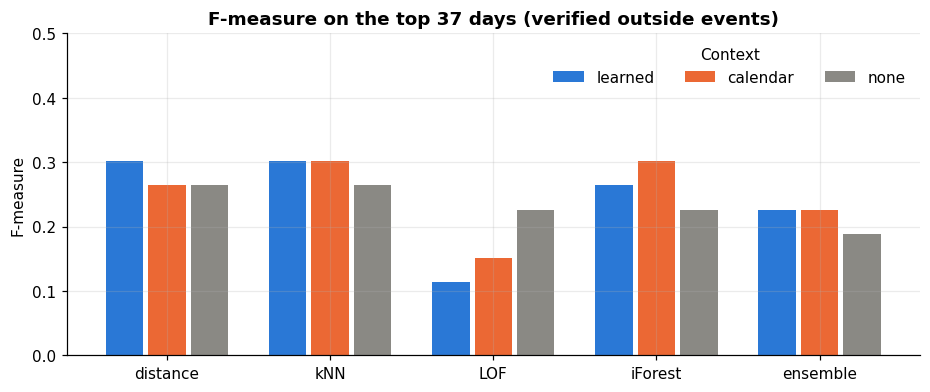

In [6]:
t = main[37][main[37].detector.isin(DETECTORS)]
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.26
x = np.arange(len(DETECTORS))
for i, (ctx, color) in enumerate([("learned", BLUE), ("calendar", ORANGE), ("none", GREY)]):
    vals = t[t.context == ctx].set_index("detector").loc[DETECTORS, "F"]
    ax.bar(x + (i - 1) * width, vals, width=width - 0.03, color=color, label=ctx)
ax.set(title="F-measure on the top 37 days (verified outside events)", xticks=x, xticklabels=DETECTORS,
       ylabel="F-measure", ylim=(0, 0.5))
ax.legend(frameon=False, title="Context", ncol=3, loc="upper right")
plt.show()

**Main result: the learned contexts do not detect the verified events better than the calendar contexts.** Across detectors and both values of k, the two are close, and which one is ahead changes from detector to detector. The research hypothesis is therefore **not supported** on this data.

How large are these differences? With only 16 event-days, **one** extra detected day changes recall by about 0.06 and the F-measure by about 0.05. Most differences between learned and calendar are one or two days, which is within what chance alone could produce. Using some context is somewhat better than no context for the ensemble and Isolation Forest, but not for every detector.

**The exception: the GMM likelihood.** The learned context's extra detector, the GMM likelihood from Step 5, is the **best detector overall** (F-measure 0.44 on the top 20, with 8 of the 16 event-days; 0.34 on the top 37). Section 4b checks where this advantage comes from.

**Why the residual-based detectors show no difference.** The clearest anomalies (Hurricane Sandy, Hurricane Irene, the January 2011 snowstorm, the October 2011 storm) are days with a **huge drop in level**: far fewer rentals than similar nearby days. That drop is visible under *any* context. The context mostly changes how the day's *shape* is judged, and the calendar baseline already includes wet versus dry weather, which is what the learned rainy types capture too.

## 4b. Post-hoc check: is it the learned groups or the likelihood method?

*This check was added after seeing the GMM result in Section 4, so it is reported as an extra analysis, not as part of the pre-registered comparison.*

The GMM likelihood has no calendar equivalent in the main comparison. To separate the effect of the **groups** from the effect of the **likelihood method**, the same kind of model is fitted to every context: one Gaussian per group, on the same 4 principal components, and each day is scored by how unlikely it is under its own group's Gaussian.

In [7]:
from scipy.stats import multivariate_normal

Z = pd.read_csv("pca_scores_all.csv", index_col="dteday", parse_dates=True)

def gaussian_per_group(groups):
    neg_ll = pd.Series(index=Z.index, dtype=float)
    for _, idx in Z.groupby(groups).groups.items():
        x = Z.loc[idx].values
        cov = np.cov(x.T) + 1e-6 * np.eye(x.shape[1])          # tiny ridge keeps the covariance invertible
        neg_ll[idx] = -multivariate_normal(x.mean(axis=0), cov).logpdf(x)
    return neg_ll

likelihood_models = {
    "GMM, learned day types (soft membership)": -clusters.log_likelihood,
    "one Gaussian per learned day type": gaussian_per_group(CONTEXTS["learned"]),
    "one Gaussian per calendar group": gaussian_per_group(CONTEXTS["calendar"]),
    "one Gaussian for all days (no context)": gaussian_per_group(CONTEXTS["none"]),
}
rows = []
for name, score in likelihood_models.items():
    row = {"model": name}
    for k in [20, 37]:
        p, r, f1, hits = prf(score, OUTSIDE, k)
        row[f"hits in top {k}"], row[f"F (top {k})"] = hits, round(f1, 2)
    rows.append(row)
pd.DataFrame(rows).set_index("model")

,hits in top 20,F (top 20),hits in top 37,F (top 37)
model,,,,
"GMM, learned day types (soft membership)",8,0.44,9,0.34
one Gaussian per learned day type,7,0.39,8,0.30
one Gaussian per calendar group,4,0.22,7,0.26
one Gaussian for all days (no context),6,0.33,8,0.30


**Result.** Among likelihood-based detectors, the **learned day types do better than the calendar groups**: the GMM finds 8 of the 16 event-days in its top 20, one Gaussian per calendar group finds 4, and a single Gaussian with no context finds 6. With soft membership (the GMM) the learned types do slightly better than with hard assignment.

So the answer to the main question is more nuanced than Section 4 alone suggests: **learned contexts help when they are used as a probabilistic model of normal days, but not when only the distance to a typical day is measured.**

Three reasons for caution: the check was added after seeing results; the margin is a few days out of 16; and the smallest calendar groups have only 11 days, which makes their Gaussian estimates noisier than those of the larger learned types, so part of the gap may come from group size rather than from how the groups were formed.

## 5. Which events are found, and which are missed?

In [8]:
rank = {ctx: S[ctx]["ensemble"].rank(ascending=False) for ctx in ["learned", "calendar", "none"]}
rows = []
for r in events[events.type != "holiday"].itertuples():
    for d in pd.date_range(r.start_date, r.end_date):
        rows.append({"date": d.date(), "event": r.event[:55], "type": r.type,
                     **{f"rank ({ctx})": int(rank[ctx][d]) for ctx in rank}})
found = pd.DataFrame(rows)
found["in top 37 (learned)"] = found["rank (learned)"] <= 37
found

,date,event,type,rank (learned),rank (calendar),rank (none),in top 37 (learned)
0,2011-01-26,Snowstorm during the evening commute ('Commuta...,weather,20,20,22,True
1,2011-03-29,Cherry blossom peak bloom (Tidal Basin),public event,447,453,506,False
2,2011-08-23,Magnitude 5.8 Virginia earthquake at 1:51 p.m....,disruption,78,43,113,False
3,2011-08-27,"Hurricane Irene: gusts over 50 mph, about 4 in...",weather,1,1,2,True
4,2011-08-28,"Hurricane Irene: gusts over 50 mph, about 4 in...",weather,9,12,79,True
5,2011-09-06,"Remnants of Tropical Storm Lee: heavy rain, wo...",weather,138,74,59,False
6,2011-09-07,"Remnants of Tropical Storm Lee: heavy rain, wo...",weather,41,70,49,False
7,2011-09-08,"Remnants of Tropical Storm Lee: heavy rain, wo...",weather,75,68,86,False
8,2011-09-09,"Remnants of Tropical Storm Lee: heavy rain, wo...",weather,91,78,109,False
9,2011-10-29,Early-season winter storm; only a trace of sno...,weather,11,9,4,True


Ranks are out of 731 days (1 = most anomalous).

- **Found by all contexts:** the large storms, where demand collapsed: the January 2011 snowstorm, Hurricane Irene, the October 2011 storm and Hurricane Sandy.
- **Missed by all contexts:** the cherry blossom peaks, the record heat day, most days of Tropical Storm Lee and the derecho (which arrived late in the evening, after most riding). The earthquake comes close under the calendar context (rank 43) but stays outside the top 37. These events changed demand only a little, or only for one rider group, which is what Section 8 examines.

## 6. Including holidays (secondary result)

In [9]:
secondary = evaluation_table(ALL_EVENTS, 37)
display(secondary.pivot(index="detector", columns="context", values="F").round(2).loc[DETECTORS + ["GMM likelihood"]])

hol_days = [d for d in ALL_EVENTS - OUTSIDE]
hol_rank = S["learned"]["ensemble"].rank(ascending=False)[hol_days]
print(f"Holidays in the top 37 (learned ensemble): {(hol_rank <= 37).sum()} of {len(hol_days)}; "
      f"median rank {hol_rank.median():.0f} of 731")

context,calendar,learned,none
detector,,,
distance,0.30,0.30,0.24
kNN,0.30,0.27,0.30
LOF,0.27,0.14,0.22
iForest,0.30,0.19,0.22
ensemble,0.27,0.24,0.14
GMM likelihood,NaN,0.30,NaN


Holidays in the top 37 (learned ensemble): 3 of 21; median rank 95 of 731


**Holidays are rarely anomalous.** Only 3 of the 21 holidays reach the top 37. Both contexts treat a holiday like a day off (15 of the 21 holidays fall into the two day-off types, and the calendar marks all of them as non-working), and people mostly ride on holidays the way they ride on weekends. So a holiday is a *calendar event* but not a *demand anomaly*. Counting holidays as anomalies to be found lowers every method's score, which is why the outside events are the main ground truth. This is itself a useful finding for the bike company: holidays need weekend planning, not special treatment.

## 7. Are the flagged days explainable?

The events list is incomplete: a flagged day that is not on it may still be a real event. The rule fixed at the start sorts every flagged day into *verified*, *plausible* or *unexplained*. Because the plausible rule is broad, its **base rate** over all 731 days is shown for comparison: a method is only useful if its flagged days are explainable much more often than random days.

In [10]:
def explain(d):
    if d in ALL_EVENTS:
        return "verified event"
    r = feat.loc[d]
    if r.bad_weather_daytime_hours >= 3 or abs(r.temp_anomaly_c) >= 4 or r.days_to_holiday <= 1 or r.bridge_day == 1:
        return "plausible"
    return "unexplained"

ORDER = ["verified event", "plausible", "unexplained"]
base = pd.Series([explain(d) for d in feat.index]).value_counts(normalize=True).reindex(ORDER, fill_value=0)
rows = {"all 731 days (base rate)": base}
for ctx in ["learned", "calendar", "none"]:
    for k in [20, 37]:
        top = S[ctx]["ensemble"].nlargest(k).index
        rows[f"{ctx}, top {k}"] = pd.Series([explain(d) for d in top]).value_counts(normalize=True).reindex(ORDER, fill_value=0)
pd.DataFrame(rows).T.style.format("{:.0%}")

,verified event,plausible,unexplained
all 731 days (base rate),5%,30%,65%
"learned, top 20",30%,65%,5%
"learned, top 37",24%,62%,14%
"calendar, top 20",40%,60%,0%
"calendar, top 37",27%,62%,11%
"none, top 20",20%,80%,0%
"none, top 37",14%,76%,11%


**Result.** Only about a third of all days have any verified or plausible explanation, but **about 90 to 100% of the top 20 days** do, under every context. All methods therefore pick out genuinely unusual days rather than noise. The learned and calendar contexts again perform about the same.

In [11]:
top20 = S["learned"]["ensemble"].nlargest(20).index
explained = feat.loc[top20, ["day_type", "workingday", "bad_weather_daytime_hours", "temp_anomaly_c",
                             "level_casual", "level_registered", "bridge_day"]].round(2)
explained.insert(0, "weekday", top20.strftime("%a"))
explained["explanation"] = [explain(d) for d in top20]
explained["event"] = [", ".join(events.loc[(pd.to_datetime(events.start_date) <= d) & (pd.to_datetime(events.end_date) >= d), "event"].str[:35]) for d in top20]
explained

,weekday,day_type,workingday,bad_weather_daytime_hours,temp_anomaly_c,level_casual,level_registered,bridge_day,explanation,event
dteday,,,,,,,,,,
2011-08-27,Sat,Rainy day off,0,10,-0.09,-2.73,-1.56,0,verified event,"Hurricane Irene: gusts over 50 mph,"
2012-10-29,Mon,Rainy day off,1,14,-1.79,-8.47,-8.03,0,verified event,Hurricane Sandy: federal offices cl
2012-04-22,Sun,Rainy day off,0,14,-4.38,-4.22,-2.17,0,plausible,
2012-12-26,Wed,Warm working day,1,14,-1.23,-5.12,-3.24,0,plausible,
2011-03-06,Sun,Rainy day off,0,8,2.69,-2.49,-1.54,0,plausible,
2011-01-18,Tue,Rainy working day,1,5,0.85,-2.81,-1.02,0,plausible,
2012-10-30,Tue,Rainy day off,1,12,-4.54,-2.93,-2.37,0,verified event,Hurricane Sandy: federal offices cl
2012-01-01,Sun,Rainy day off,0,2,3.53,1.18,-0.33,0,plausible,
2011-08-28,Sun,Rainy day off,0,2,0.58,-0.09,0.15,0,verified event,"Hurricane Irene: gusts over 50 mph,"


**Notable days in the top 20 (learned contexts)** beyond the verified storms:

- **Christmas Eve 2012**, a bridge day: officially a working day, but registered riders (commuters) were far below normal. The calendar label is wrong for that day, and the learned contexts place it with days off.
- **New Year's Day 2011 and 2012**: New Year's Day fell on a Saturday and a Sunday, so the dataset's holiday flag sits on the observed weekday instead (2 January 2012; for 2011 the observed day falls before the data starts). On the actual New Year's Day, casual riding was above normal, on an unusually mild winter day.
- **Several days with 10 to 14 hours of rain or snow** that are not in the events list. They are plausible weather anomalies, but they were not verified against an outside source, so they are reported as plausible only.

## 8. Second research question: which rider group drives each anomaly?

The same procedure (learned contexts, ensemble detector) is run separately on casual and on registered riders. Each day then has two scores. A day is called anomalous for a group if it is in that group's top 5% (about 37 days).

| Zone | Meaning |
| --- | --- |
| both | the whole system was disrupted |
| casual only | leisure demand behaved unusually |
| registered only | commuting demand behaved unusually |
| neither | a normal day |

In [12]:
group_scores = pd.DataFrame({
    g: detect(residuals(CONTEXTS["learned"], g), feat.index)["ensemble"] for g in ["casual", "registered"]})
threshold = group_scores.quantile(0.95)
hi_c = group_scores.casual > threshold.casual
hi_r = group_scores.registered > threshold.registered
group_scores["zone"] = np.select([hi_c & hi_r, hi_c, hi_r], ["both", "casual only", "registered only"], "neither")
group_scores.zone.value_counts()

zone
neither            673
registered only     21
casual only         21
both                16
Name: count, dtype: int64

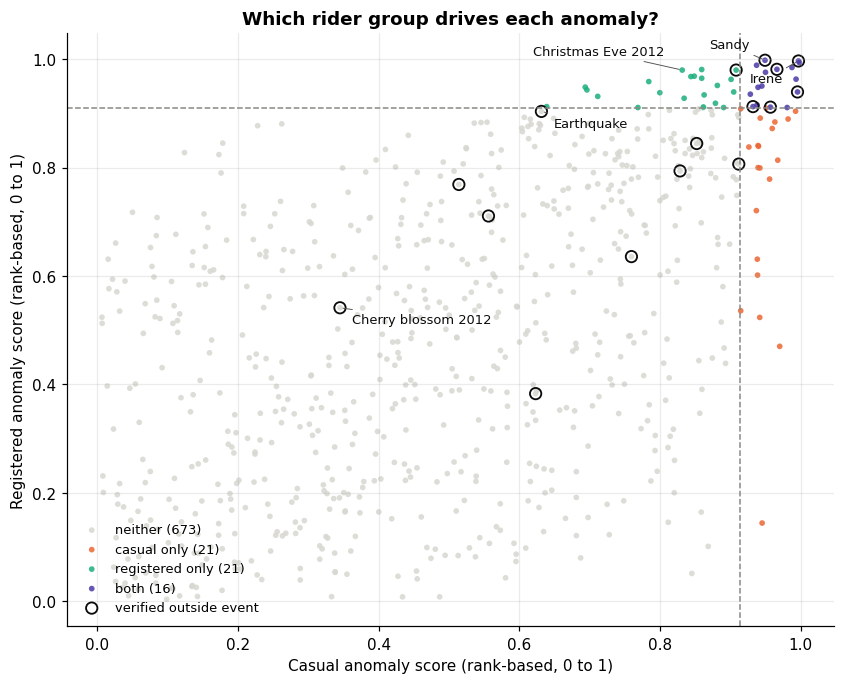

In [13]:
zone_colors = {"neither": "#d8d7d2", "casual only": ORANGE, "registered only": AQUA, "both": VIOLET}
fig, ax = plt.subplots(figsize=(9, 7))
for zone, color in zone_colors.items():
    sel = group_scores.zone == zone
    ax.scatter(group_scores.casual[sel], group_scores.registered[sel], s=14, color=color,
               edgecolors="none", alpha=0.85, label=f"{zone} ({sel.sum()})")
ev_days = sorted(OUTSIDE)
ax.scatter(group_scores.casual[ev_days], group_scores.registered[ev_days], s=55, facecolors="none",
           edgecolors="#0b0b0b", linewidths=1.2, label="verified outside event")
ax.axvline(threshold.casual, color=GREY, linewidth=1, linestyle="--")
ax.axhline(threshold.registered, color=GREY, linewidth=1, linestyle="--")
# (label, x offset, y offset, alignment) chosen so labels in the crowded top-right corner do not collide
labels = {"2012-10-29": ("Sandy", -10, 8, "right"), "2011-08-27": ("Irene", -10, -14, "right"),
          "2012-12-24": ("Christmas Eve 2012", -12, 10, "right"), "2011-08-23": ("Earthquake", 8, -10, "left"),
          "2012-03-20": ("Cherry blossom 2012", 8, -10, "left")}
for d, (text, dx, dy, ha) in labels.items():
    d = pd.Timestamp(d)
    ax.annotate(text, (group_scores.casual[d], group_scores.registered[d]), xytext=(dx, dy), ha=ha,
                textcoords="offset points", fontsize=8.5, color="#0b0b0b",
                arrowprops=dict(arrowstyle="-", color="#52514e", linewidth=0.6))
ax.set(title="Which rider group drives each anomaly?", xlabel="Casual anomaly score (rank-based, 0 to 1)",
       ylabel="Registered anomaly score (rank-based, 0 to 1)")
ax.legend(frameon=False, loc="lower left", fontsize=8.5)
plt.show()

In [14]:
rows = []
for r in events[events.type != "holiday"].itertuples():
    for d in pd.date_range(r.start_date, r.end_date):
        rows.append({"date": d.date(), "event": r.event[:45], "expected group": r.expected_group,
                     "zone": group_scores.zone[d],
                     "casual rank": int(group_scores.casual.rank(ascending=False)[d]),
                     "registered rank": int(group_scores.registered.rank(ascending=False)[d])})
pd.DataFrame(rows)

,date,event,expected group,zone,casual rank,registered rank
0,2011-01-26,Snowstorm during the evening commute ('Commut,both,both,33,31
1,2011-03-29,Cherry blossom peak bloom (Tidal Basin),casual,neither,266,461
2,2011-08-23,Magnitude 5.8 Virginia earthquake at 1:51 p.m,registered,neither,256,45
3,2011-08-27,"Hurricane Irene: gusts over 50 mph, about 4 i",both,both,2,2
4,2011-08-28,"Hurricane Irene: gusts over 50 mph, about 4 i",both,registered only,43,9
5,2011-09-06,"Remnants of Tropical Storm Lee: heavy rain, w",both,neither,100,141
6,2011-09-07,"Remnants of Tropical Storm Lee: heavy rain, w",both,both,14,34
7,2011-09-08,"Remnants of Tropical Storm Lee: heavy rain, w",both,neither,85,91
8,2011-09-09,"Remnants of Tropical Storm Lee: heavy rain, w",both,neither,39,128
9,2011-10-29,Early-season winter storm; only a trace of sn,both,both,3,22


**Testing the expected groups from the events list** (these were hypotheses written before any scoring):

- **Large storms (the first day of Irene, Sandy, the January and October storms) fall in "both"**, as expected: the whole system stops. The second day of Irene, a Sunday after the storm had passed, is registered-only.
- **The earthquake behaves as predicted for commuters:** it ranks far higher for registered riders than for casual riders, but stays just outside the top 5%. A disruption at 13:51 on a working day mainly changed when commuters went home.
- **The cherry blossom peaks are not anomalous for casual riders**, against the expectation. A likely reason is that the blossoms draw visitors over several weeks, so the peak day itself is not special compared with the days around it.
- **The record heat day is not anomalous for either group.**

So the rider-group split explains *some* events (storms, the earthquake) and shows that others were weaker than expected.

In [15]:
def describe_zone(zone, by):
    idx = group_scores[group_scores.zone == zone].sort_values(by, ascending=False).index[:8]
    t = feat.loc[idx, ["day_type", "bad_weather_daytime_hours", "temp_anomaly_c", "level_casual", "level_registered"]].round(2)
    t.insert(0, "weekday", idx.strftime("%a"))
    t["explanation"] = [explain(d) for d in idx]
    return t

print("Casual only (strongest 8)")
display(describe_zone("casual only", "casual"))
print("Registered only (strongest 8)")
display(describe_zone("registered only", "registered"))
pd.crosstab(group_scores.zone, [explain(d) for d in group_scores.index]).reindex(columns=ORDER, fill_value=0)

Casual only (strongest 8)


,weekday,day_type,bad_weather_daytime_hours,temp_anomaly_c,level_casual,level_registered,explanation
dteday,,,,,,,
2011-04-16,Sat,Rainy day off,10,-1.57,-3.30,-1.70,plausible
2012-02-29,Wed,Rainy working day,7,-0.85,-2.15,-1.21,plausible
2011-01-07,Fri,Cool working day,0,-0.35,0.95,-0.01,unexplained
2012-12-09,Sun,Normal day off,8,1.16,-0.28,-0.11,plausible
2011-10-01,Sat,Normal day off,7,-5.90,-1.69,-0.70,plausible
2011-11-29,Tue,Rainy working day,8,3.23,-0.91,-0.17,plausible
2011-04-12,Tue,Warm working day,6,2.68,-0.68,-0.43,plausible
2011-02-28,Mon,Rainy working day,8,4.84,-1.36,-0.32,plausible


Registered only (strongest 8)


,weekday,day_type,bad_weather_daytime_hours,temp_anomaly_c,level_casual,level_registered,explanation
dteday,,,,,,,
2011-01-18,Tue,Rainy working day,5,0.85,-2.81,-1.02,plausible
2012-12-24,Mon,Rainy day off,7,-2.67,-0.85,-2.55,plausible
2011-08-28,Sun,Rainy day off,2,0.58,-0.09,0.15,verified event
2011-01-01,Sat,Rainy day off,2,5.07,0.91,-0.34,plausible
2012-12-29,Sat,Rainy working day,4,0.13,-1.36,-0.28,plausible
2011-04-23,Sat,Rainy day off,1,-2.83,0.06,0.05,unexplained
2011-02-05,Sat,Rainy day off,10,1.20,-1.13,-0.20,plausible
2011-01-27,Thu,Rainy working day,9,1.07,-1.94,-1.81,plausible


col_0,verified event,plausible,unexplained
zone,,,
both,6,8,2
casual only,0,17,4
neither,29,178,466
registered only,2,14,5


**Reading the zones.**

- **Casual-only days** are mostly rainy days on which casual demand fell clearly, often to half or less of its usual level, while registered demand fell much less. Leisure riders cancel in bad weather; commuters mostly do not.
- **Registered-only days** include Christmas Eve 2012 and days next to holidays, when commuting stopped but leisure riding did not, plus the second day of Irene.
- In every zone except "neither", most days are verified or plausible.

## 9. What this means for the bike company

1. **Storm days are easy to detect with any method**, because demand collapses. A simple level alarm (today's rentals compared with similar recent days) catches them, with no clustering needed.
2. **Rainy days hit casual riders far harder than commuters.** On rainy days, plan fewer bikes at leisure locations, but keep commuter stations stocked.
3. **Holidays behave like weekends.** Plan them as weekends; they are not disruptions.
4. **Bridge days such as Christmas Eve are mislabelled by the calendar.** Officially working days, they behave like days off for commuters. Treating them as days off would improve staffing and rebalancing plans.
5. **Watch the casual-only and registered-only alerts separately.** They point to different actions: leisure demand (marketing, day passes, tourist stations) versus commuting demand (reliability at business districts).

## 10. Save

In [16]:
out = pd.DataFrame(index=feat.index)
for ctx in ["learned", "calendar", "none"]:
    for det in S[ctx].columns:
        out[f"{ctx}_{det}"] = S[ctx][det]
out = out.join(group_scores.rename(columns={"casual": "casual_ensemble", "registered": "registered_ensemble",
                                            "zone": "rider_zone"}))
out["explanation"] = [explain(d) for d in out.index]
out["verified_event"] = out.index.isin(sorted(ALL_EVENTS))
out.to_csv("anomaly_scores.csv")
print(f"Saved anomaly_scores.csv: {out.shape[0]} days x {out.shape[1]} columns")

Saved anomaly_scores.csv: 731 days x 21 columns


## Summary for the report

- **Main question:** with the distance-based detectors (distance, kNN, LOF, Isolation Forest, ensemble), learned day types and calendar contexts detect the verified outside events **about equally well**, within one or two detected days of each other. When the contexts are used as **probabilistic models**, the learned day types do better: the GMM likelihood is the best detector overall (8 of 16 event-days in the top 20, against 4 for Gaussians fitted to the calendar groups). This last comparison was added after seeing results and the margin is small, so the hypothesis is **partly supported at best**.
- **What every method finds:** the big storms (January 2011 snowstorm, Irene, October 2011 storm, Sandy). Around 90 to 100% of the top 20 days have a verified or plausible explanation, against about a third of all days.
- **What no method finds:** the cherry blossom peaks, the record heat day, the derecho and most of Tropical Storm Lee; these changed demand only a little.
- **Holidays are not anomalies:** they behave like weekends under both contexts.
- **Second question:** storms disrupt both rider groups; the earthquake mainly affected commuters; rainy days hit casual riders much harder than registered riders; bridge days such as Christmas Eve are registered-only anomalies that the calendar mislabels.

**Limitations.** The likelihood comparison (Section 4b) was added after the main results were seen. Only 16 verified outside event-days, so differences of one or two detections are not meaningful. The events list cannot be complete, so precision is underestimated. The plausible rule is broad and is only a rough check. The learned contexts depend on the clustering choice in Step 5, whose finer structure was partly method-dependent.